# 📊 Bedah Kasus 1 – 3: Tipe Data & Visualisasi Data

| | |
|---|---|
| **Nama** | **Stefhanus Christopher Hasiholan Simarmata** |
| **NIM** | **241051014** |

Notebook ini mengerjakan tiga bedah kasus dari gambar tugas:

1. **Bedah Kasus 1** — Dataset Operasional Penjualan
2. **Bedah Kasus 2** — Dataset Profil Mahasiswa
3. **Bedah Kasus 3** — Dataset Pengamatan Cuaca

**Alur pengerjaan:** (0) Setup → (1) Data sintetis 1.000 baris → (2) Analisis Kasus 1 → (3) Analisis Kasus 2 → (4) Analisis Kasus 3 → (5) Kesimpulan & dashboard Streamlit.

## 0. Konsep: Tipe Data → Visualisasi yang Sesuai

| Tipe data | Ciri utama | Contoh di tugas | Visualisasi yang sesuai |
|---|---|---|---|
| 🔵 **Kategorik – Nominal** | Label pembeda, tanpa urutan | Produk, Kategori, Jurusan, Kota, Kondisi | Bar Chart, Pie Chart |
| 🔵 **Kategorik – Ordinal** | Ada tingkatan/urutan jelas | Semester (1 → 8) | Bar Chart **berurutan** |
| 🟠 **Numerik Diskrit – Rasio** | Hasil hitung bilangan bulat, nol absolut | Jumlah Terjual | Histogram / Bar |
| 🟠 **Numerik Kontinu – Rasio** | Rentang/desimal, nol absolut | Harga, IPK, Usia, Kelembaban | Histogram, Box Plot |
| 🟠 **Numerik – Interval** | Jarak sama, **nol tidak absolut** (rasio tak berlaku) | Suhu (°C) | Histogram, Box Plot |
| ⚪ **Waktu – Interval** | Urutan waktu | Tanggal | Line Chart (tren) |

### Setup: library, tema, dan fungsi bantu

In [1]:
import warnings
warnings.filterwarnings("ignore")

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats
from IPython.display import display, Markdown

# ====== IDENTITAS ======
NAMA, NIM = "Stefhanus Christopher Hasiholan Simarmata", "241051014"

# Warna konsisten dengan gambar tugas: biru = kategorik, oranye = numerik, abu = waktu
BIRU, ORANYE, ABU = "#3B9AE1", "#F29E38", "#7A8591"

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 100, "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.spines.top": False, "axes.spines.right": False,
})
pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_columns", 50)


def fmt_rp(x, pos=None):
    """Format rupiah ringkas untuk sumbu grafik."""
    for batas, sat in [(1e12, "T"), (1e9, "M"), (1e6, "jt"), (1e3, "rb")]:
        if abs(x) >= batas:
            return f"Rp {x / batas:,.1f} {sat}".replace(".", ",").replace(",0 ", " ")
    return f"Rp {x:,.0f}"


def finalize(fig, judul=None):
    """Judul + watermark Nama/NIM pada setiap grafik, lalu tampilkan."""
    if judul:
        fig.suptitle(judul, fontsize=15, fontweight="bold")
    fig.tight_layout(rect=[0, 0.03, 1, 0.96 if judul else 1])
    fig.text(0.995, 0.006, f"{NAMA}  •  NIM {NIM}", ha="right", va="bottom",
             fontsize=8.5, color="#777777", style="italic")
    plt.show()


def ringkasan_numerik(df, kolom):
    """Statistik deskriptif lengkap (lebih detail dari describe())."""
    out = {}
    for k in kolom:
        s = df[k].dropna()
        q1, q3 = s.quantile(0.25), s.quantile(0.75)
        out[k] = {"Count": s.count(), "Mean": s.mean(), "Median": s.median(),
                  "Std": s.std(), "Min": s.min(), "Q1": q1, "Q3": q3, "Max": s.max(),
                  "IQR": q3 - q1, "Skewness": s.skew(), "Kurtosis": s.kurt(),
                  "CV (%)": s.std() / s.mean() * 100}
    return pd.DataFrame(out).T


def outlier_iqr(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    bb, ba = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return (s < bb) | (s > ba), bb, ba


print("=" * 52)
print(f" Nama : {NAMA}")
print(f" NIM  : {NIM}")
print("=" * 52)

 Nama : Stefhanus Christopher Hasiholan Simarmata
 NIM  : 241051014


## 1. Pembuatan Data Sintetis (1.000 baris per kasus)

Data dibuat berdasarkan struktur & tipe data pada gambar, dengan aturan agar **realistis**:

- **Kasus 1 – Penjualan:** 17 produk dalam 5 kategori; harga mengikuti harga dasar produk + variasi promo (dibulatkan Rp500); jumlah terjual ~ Poisson (lebih mahal → lebih sedikit); ada **tren naik** pada volume transaksi/unit dan **pola musiman** (Harbolnas, tahun ajaran baru, dll.), periode 2024–2025.
- **Kasus 2 – Mahasiswa:** 8 jurusan; semester 1–8; **usia konsisten dengan semester**; IPK ~ normal per jurusan, dengan sedikit mahasiswa ber-IPK rendah (outlier) dan mahasiswa berusia lebih tua.
- **Kasus 3 – Cuaca:** 10 kota dengan iklim berbeda; suhu ~ normal per kota; **kelembaban berkorelasi negatif dengan suhu**; kondisi cuaca (Cerah/Berawan/Hujan/Hujan Lebat) bergantung pada kelembaban.

Seed = NIM, sehingga hasil **reproducible**.

In [2]:
import numpy as np
import pandas as pd

SEED = 241051019  # seed = NIM, supaya data selalu reproducible


# ----------------------------------------------------------------------
# BEDAH KASUS 1 - Dataset Operasional Penjualan
# ----------------------------------------------------------------------
KATALOG_PRODUK = {
    # produk: (kategori, harga_dasar, rata2_unit_per_transaksi, bobot_populer)
    "Laptop":            ("Elektronik",    8_500_000, 40, 0.8),
    "Smartphone":        ("Elektronik",    4_200_000, 55, 1.4),
    "Headphone":         ("Elektronik",      650_000, 70, 1.0),
    "Smartwatch":        ("Elektronik",    1_800_000, 35, 0.6),
    "Buku":              ("Pendidikan",       75_000, 120, 1.6),
    "Alat Tulis":        ("Pendidikan",       25_000, 150, 1.3),
    "Kalkulator":        ("Pendidikan",      185_000, 60, 0.7),
    "Tas Ransel":        ("Pendidikan",      280_000, 50, 0.9),
    "Kemeja":            ("Fashion",         225_000, 65, 1.2),
    "Sepatu Sneakers":   ("Fashion",         550_000, 45, 1.1),
    "Jaket":             ("Fashion",         375_000, 40, 0.8),
    "Rice Cooker":       ("Rumah Tangga",    450_000, 38, 0.8),
    "Blender":           ("Rumah Tangga",    320_000, 42, 0.7),
    "Set Peralatan Masak": ("Rumah Tangga",  600_000, 30, 0.5),
    "Matras Yoga":       ("Olahraga",        190_000, 48, 0.6),
    "Dumbbell":          ("Olahraga",        260_000, 36, 0.5),
    "Sepeda Lipat":      ("Olahraga",      4_800_000, 12, 0.3),
}


def _faktor_musiman(kategori, bulan):
    """Pola musiman sederhana per kategori (mis. Harbolnas, tahun ajaran baru)."""
    if kategori == "Elektronik" and bulan in (11, 12):
        return 1.35
    if kategori == "Pendidikan" and bulan in (1, 7, 8):
        return 1.40
    if kategori == "Fashion" and bulan in (3, 4, 12):
        return 1.30
    if kategori == "Olahraga" and bulan in (1, 9):
        return 1.20
    return 1.0


def buat_data_penjualan(n=1000, seed=SEED):
    rng = np.random.default_rng(seed)
    produk = list(KATALOG_PRODUK)
    bobot = np.array([KATALOG_PRODUK[p][3] for p in produk])
    bobot = bobot / bobot.sum()

    # Tanggal: 2 tahun, transaksi makin ramai seiring waktu (tren naik)
    hari = pd.date_range("2024-01-01", "2025-12-31", freq="D")
    p_hari = 1 + 0.6 * np.arange(len(hari)) / len(hari)
    p_hari = p_hari / p_hari.sum()
    tanggal = np.sort(rng.choice(hari, size=n, p=p_hari))

    pilih = rng.choice(produk, size=n, p=bobot)
    rows = []
    for p, t in zip(pilih, pd.to_datetime(tanggal)):
        kat, harga_dasar, lam, _ = KATALOG_PRODUK[p]
        # harga bervariasi (promo / varian) lalu dibulatkan ke kelipatan Rp500
        harga = harga_dasar * rng.normal(1.0, 0.07)
        harga = max(harga, harga_dasar * 0.7)
        harga = int(round(harga / 500) * 500)
        # jumlah terjual: hasil hitung bulat (Poisson) + pola musiman
        tumbuh = 1 + 0.35 * (t - hari[0]).days / len(hari)      # pertumbuhan bisnis ~35% / 2 th
        lam_eff = lam * _faktor_musiman(kat, t.month) * tumbuh
        jumlah = int(max(1, rng.poisson(lam_eff)))
        rows.append((p, kat, harga, jumlah, t))

    df = pd.DataFrame(rows, columns=["Produk", "Kategori", "Harga (Rp)",
                                     "Jumlah Terjual", "Tanggal"])
    return df


# ----------------------------------------------------------------------
# BEDAH KASUS 2 - Dataset Profil Mahasiswa
# ----------------------------------------------------------------------
JURUSAN = {
    # jurusan: (bobot, rata2 IPK)
    "Sistem Informasi":    (0.18, 3.35),
    "Teknik Informatika":  (0.17, 3.20),
    "Manajemen":           (0.17, 3.38),
    "Akuntansi":           (0.13, 3.30),
    "Psikologi":           (0.11, 3.45),
    "Ilmu Komunikasi":     (0.10, 3.40),
    "Teknik Sipil":        (0.08, 3.10),
    "Hukum":               (0.06, 3.25),
}


def buat_data_mahasiswa(n=1000, seed=SEED):
    rng = np.random.default_rng(seed + 1)
    nama_j = list(JURUSAN)
    bobot_j = np.array([JURUSAN[j][0] for j in nama_j])
    bobot_j = bobot_j / bobot_j.sum()

    jurusan = rng.choice(nama_j, size=n, p=bobot_j)
    # semester 1-8 : mahasiswa semester awal lebih banyak (ada yang berhenti/lulus)
    bobot_s = np.array([0.17, 0.15, 0.15, 0.13, 0.13, 0.11, 0.09, 0.07])
    semester = rng.choice(np.arange(1, 9), size=n, p=bobot_s / bobot_s.sum())

    # Usia konsisten dengan semester: masuk kuliah ~18 th, naik 1 th per 2 semester
    usia = 18 + (semester - 1) // 2 + rng.choice([0, 0, 0, 1, 1, 2], size=n)
    senior = rng.random(n) < 0.03                     # mahasiswa kerja / usia lebih tua
    usia = np.where(senior, usia + rng.integers(3, 8, size=n), usia)
    usia = np.clip(usia, 17, 30)

    # IPK ~ normal per jurusan, sedikit naik seiring semester (seleksi alam), plus outlier rendah
    mu = np.array([JURUSAN[j][1] for j in jurusan]) + 0.015 * (semester - 4)
    ipk = rng.normal(mu, 0.30)
    rendah = rng.random(n) < 0.03
    ipk = np.where(rendah, rng.uniform(1.8, 2.5, size=n), ipk)
    ipk = np.round(np.clip(ipk, 1.8, 4.0), 2)

    return pd.DataFrame({"Jurusan": jurusan, "Semester": semester,
                         "IPK": ipk, "Usia": usia})


# ----------------------------------------------------------------------
# BEDAH KASUS 3 - Dataset Pengamatan Cuaca
# ----------------------------------------------------------------------
KOTA_CUACA = {
    # kota: (rata2 suhu, sd suhu, rata2 kelembaban)
    "Jakarta":    (31.5, 1.8, 74),
    "Bandung":    (25.0, 1.8, 82),
    "Surabaya":   (32.0, 1.6, 70),
    "Medan":      (31.0, 1.8, 76),
    "Makassar":   (31.5, 1.5, 76),
    "Yogyakarta": (29.5, 1.8, 77),
    "Semarang":   (31.0, 1.6, 75),
    "Denpasar":   (30.5, 1.4, 78),
    "Palembang":  (31.5, 1.6, 77),
    "Jayapura":   (31.0, 1.5, 80),
}
KONDISI = ["Cerah", "Berawan", "Hujan", "Hujan Lebat"]
# peluang kondisi cuaca berdasarkan tingkat kelembaban (batas bawah, probabilitas)
_PELUANG_KONDISI = [
    (0,  [0.80, 0.18, 0.02, 0.00]),
    (65, [0.55, 0.35, 0.10, 0.00]),
    (75, [0.25, 0.40, 0.30, 0.05]),
    (85, [0.08, 0.27, 0.50, 0.15]),
    (92, [0.02, 0.13, 0.55, 0.30]),
]


def buat_data_cuaca(n=1000, seed=SEED):
    rng = np.random.default_rng(seed + 2)
    kota_list = list(KOTA_CUACA)
    kota = rng.choice(kota_list, size=n)
    mu_s = np.array([KOTA_CUACA[k][0] for k in kota])
    sd_s = np.array([KOTA_CUACA[k][1] for k in kota])
    mu_h = np.array([KOTA_CUACA[k][2] for k in kota])

    suhu = rng.normal(mu_s, sd_s)
    # suhu makin panas -> kelembaban relatif turun (hubungan negatif)
    kelembaban = mu_h - 4.0 * (suhu - mu_s) + rng.normal(0, 6, size=n)
    kelembaban = np.clip(np.round(kelembaban), 40, 100).astype(int)
    suhu = np.round(suhu, 1)

    kondisi = []
    for h in kelembaban:
        peluang = [p for batas, p in _PELUANG_KONDISI if h >= batas][-1]
        kondisi.append(rng.choice(KONDISI, p=peluang))

    return pd.DataFrame({"Kota": kota, "Suhu (°C)": suhu,
                         "Kelembaban (%)": kelembaban, "Kondisi": kondisi})


def buat_semua_data(n=1000, seed=SEED):
    return (buat_data_penjualan(n, seed),
            buat_data_mahasiswa(n, seed),
            buat_data_cuaca(n, seed))

In [3]:
df1, df2, df3 = buat_semua_data(n=1000, seed=SEED)

# Simpan ke CSV (dipakai juga sebagai arsip data tugas)
os.makedirs("data", exist_ok=True)
df1.to_csv("data/bedah_kasus_1_penjualan.csv", index=False)
df2.to_csv("data/bedah_kasus_2_mahasiswa.csv", index=False)
df3.to_csv("data/bedah_kasus_3_cuaca.csv", index=False)

for nama, d in [("Kasus 1 - Penjualan", df1), ("Kasus 2 - Mahasiswa", df2), ("Kasus 3 - Cuaca", df3)]:
    print(f"{nama:<22}: {d.shape[0]:,} baris x {d.shape[1]} kolom | nilai hilang = {int(d.isna().sum().sum())}")

Kasus 1 - Penjualan   : 1,000 baris x 5 kolom | nilai hilang = 0
Kasus 2 - Mahasiswa   : 1,000 baris x 4 kolom | nilai hilang = 0
Kasus 3 - Cuaca       : 1,000 baris x 4 kolom | nilai hilang = 0


**Pratinjau data** (struktur sama dengan contoh 2 baris pada gambar):

In [4]:
display(Markdown("**Kasus 1 — Penjualan**")); display(df1.head(5))
display(Markdown("**Kasus 2 — Mahasiswa**"));  display(df2.head(5))
display(Markdown("**Kasus 3 — Cuaca**"));      display(df3.head(5))

**Kasus 1 — Penjualan**

,Produk,Kategori,Harga (Rp),Jumlah Terjual,Tanggal
0,Matras Yoga,Olahraga,187000,48,2024-01-01
1,Tas Ransel,Pendidikan,283500,68,2024-01-02
2,Laptop,Elektronik,8664500,41,2024-01-02
3,Jaket,Fashion,391000,34,2024-01-02
4,Sepatu Sneakers,Fashion,574000,43,2024-01-03


**Kasus 2 — Mahasiswa**

,Jurusan,Semester,IPK,Usia
0,Teknik Informatika,1,2.71,25
1,Psikologi,1,3.73,19
2,Ilmu Komunikasi,6,3.22,21
3,Teknik Informatika,7,3.08,21
4,Teknik Informatika,5,3.11,20


**Kasus 3 — Cuaca**

,Kota,Suhu (°C),Kelembaban (%),Kondisi
0,Semarang,33.10,59,Cerah
1,Jakarta,29.90,75,Hujan
2,Jakarta,29.80,85,Hujan
3,Bandung,22.40,92,Hujan
4,Palembang,30.30,83,Cerah


---
## 2. Bedah Kasus 1 — Dataset Operasional Penjualan

| Kolom | Tipe data | Visualisasi |
|---|---|---|
| Produk, Kategori | 🔵 Kategorik (Nominal) | Bar Chart / Pie Chart |
| Harga (Rp) | 🟠 Numerik (Kontinu) – Rasio | Histogram |
| Jumlah Terjual | 🟠 Numerik (Diskrit) – Rasio | Histogram / Bar (hasil hitung bulat) |
| Tanggal | ⚪ Waktu – Interval | Line Chart (tren waktu) |

### 2.1 Struktur data & statistik deskriptif

In [5]:
df1.info()
df1["Pendapatan (Rp)"] = df1["Harga (Rp)"] * df1["Jumlah Terjual"]   # kolom turunan untuk analisis bisnis

display(Markdown("**Statistik deskriptif — kolom numerik**"))
display(ringkasan_numerik(df1, ["Harga (Rp)", "Jumlah Terjual", "Pendapatan (Rp)"]))

display(Markdown("**Kolom waktu**"))
print(f"Periode data : {df1['Tanggal'].min():%d %b %Y}  s/d  {df1['Tanggal'].max():%d %b %Y} "
      f"({(df1['Tanggal'].max() - df1['Tanggal'].min()).days + 1} hari)")

for kol in ["Kategori", "Produk"]:
    ft = df1[kol].value_counts()
    display(Markdown(f"**Distribusi frekuensi — {kol} (Nominal)**"))
    display(pd.DataFrame({"Frekuensi": ft, "Persen (%)": (ft / len(df1) * 100).round(2)}))

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Produk          1000 non-null   str           
 1   Kategori        1000 non-null   str           
 2   Harga (Rp)      1000 non-null   int64         
 3   Jumlah Terjual  1000 non-null   int64         
 4   Tanggal         1000 non-null   datetime64[us]
dtypes: datetime64[us](1), int64(2), str(2)
memory usage: 57.0 KB


**Statistik deskriptif — kolom numerik**

,Count,Mean,Median,Std,Min,Q1,Q3,Max,IQR,Skewness,Kurtosis,CV (%)
Harga (Rp),"1,000.00","1,255,863.50","320,000.00","2,203,389.30","20,000.00","181,000.00","623,750.00","10,357,000.00","442,750.00",2.29,4.43,175.45
Jumlah Terjual,"1,000.00",85.11,66.00,53.11,3.00,49.00,101.00,278.00,52.00,1.39,1.28,62.40
Pendapatan (Rp),"1,000.00","69,359,583.50","18,691,000.00","120,107,806.40","3,197,000.00","12,012,375.00","44,840,375.00","845,389,000.00","32,828,000.00",2.48,6.15,173.17


**Kolom waktu**

Periode data : 01 Jan 2024  s/d  31 Dec 2025 (731 hari)


**Distribusi frekuensi — Kategori (Nominal)**

,Frekuensi,Persen (%)
Kategori,,
Pendidikan,318,31.80
Elektronik,245,24.50
Fashion,211,21.10
Rumah Tangga,119,11.90
Olahraga,107,10.70


**Distribusi frekuensi — Produk (Nominal)**

,Frekuensi,Persen (%)
Produk,,
Buku,125,12.50
Alat Tulis,97,9.70
Smartphone,94,9.40
Kemeja,76,7.60
Sepatu Sneakers,73,7.30
Headphone,68,6.80
Jaket,62,6.20
Tas Ransel,59,5.90
Laptop,56,5.60


### 2.2 Kategorik (Nominal): Bar Chart & Pie Chart

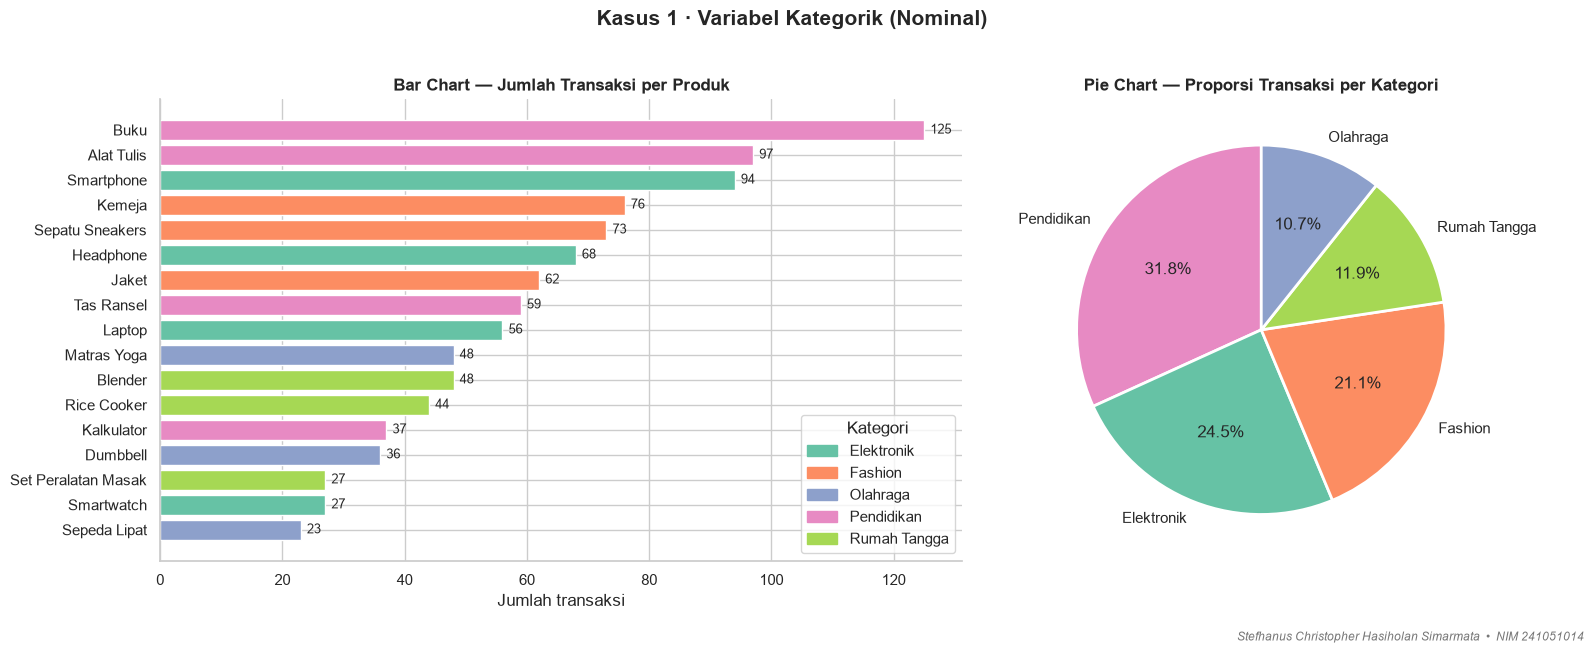

In [6]:
kat_warna = dict(zip(sorted(df1["Kategori"].unique()), sns.color_palette("Set2", 5)))
prod_kat = df1.drop_duplicates("Produk").set_index("Produk")["Kategori"]

fig, ax = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={"width_ratios": [1.5, 1]})

# Bar chart: frekuensi transaksi per produk
fp = df1["Produk"].value_counts().sort_values()
ax[0].barh(fp.index, fp.values, color=[kat_warna[prod_kat[p]] for p in fp.index])
for i, v in enumerate(fp.values):
    ax[0].text(v + 1, i, str(v), va="center", fontsize=9)
ax[0].set_title("Bar Chart — Jumlah Transaksi per Produk")
ax[0].set_xlabel("Jumlah transaksi")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in kat_warna.values()]
ax[0].legend(handles, kat_warna.keys(), title="Kategori", loc="lower right")

# Pie chart: proporsi kategori
fk = df1["Kategori"].value_counts()
ax[1].pie(fk.values, labels=fk.index, autopct="%1.1f%%", startangle=90,
          colors=[kat_warna[k] for k in fk.index], wedgeprops=dict(edgecolor="white", linewidth=2))
ax[1].set_title("Pie Chart — Proporsi Transaksi per Kategori")
finalize(fig, "Kasus 1 · Variabel Kategorik (Nominal)")

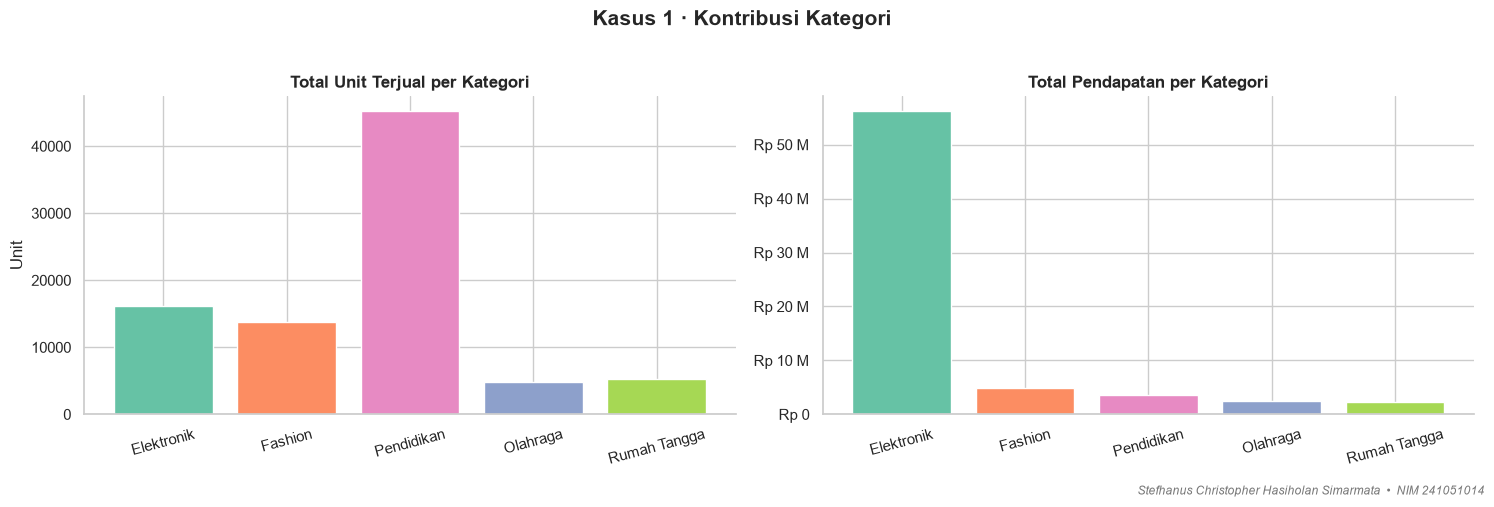

,Unit,Pendapatan,Share Pendapatan (%)
Kategori,,,
Elektronik,16171,56204434500,81.03
Fashion,13697,4875255000,7.03
Pendidikan,45216,3616912500,5.21
Olahraga,4773,2448265500,3.53
Rumah Tangga,5258,2214716000,3.19


In [7]:
# Perspektif bisnis: kategori mana yang paling berkontribusi?
agg_kat = df1.groupby("Kategori").agg(Unit=("Jumlah Terjual", "sum"), Pendapatan=("Pendapatan (Rp)", "sum")).sort_values("Pendapatan", ascending=False)

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ax[0].bar(agg_kat.index, agg_kat["Unit"], color=[kat_warna[k] for k in agg_kat.index])
ax[0].set_title("Total Unit Terjual per Kategori"); ax[0].set_ylabel("Unit")
ax[1].bar(agg_kat.index, agg_kat["Pendapatan"], color=[kat_warna[k] for k in agg_kat.index])
ax[1].yaxis.set_major_formatter(mtick.FuncFormatter(fmt_rp))
ax[1].set_title("Total Pendapatan per Kategori")
for a in ax: a.tick_params(axis="x", rotation=15)
finalize(fig, "Kasus 1 · Kontribusi Kategori")
display(agg_kat.assign(**{"Share Pendapatan (%)": agg_kat["Pendapatan"] / agg_kat["Pendapatan"].sum() * 100}))

### 2.3 Numerik: Histogram Harga (Kontinu-Rasio) & Jumlah Terjual (Diskrit-Rasio)

Harga sangat beragam (Rp25 rb – Rp10 jt), maka histogram memakai **skala log** agar semua kelompok harga terlihat; lalu dipecah per kategori.

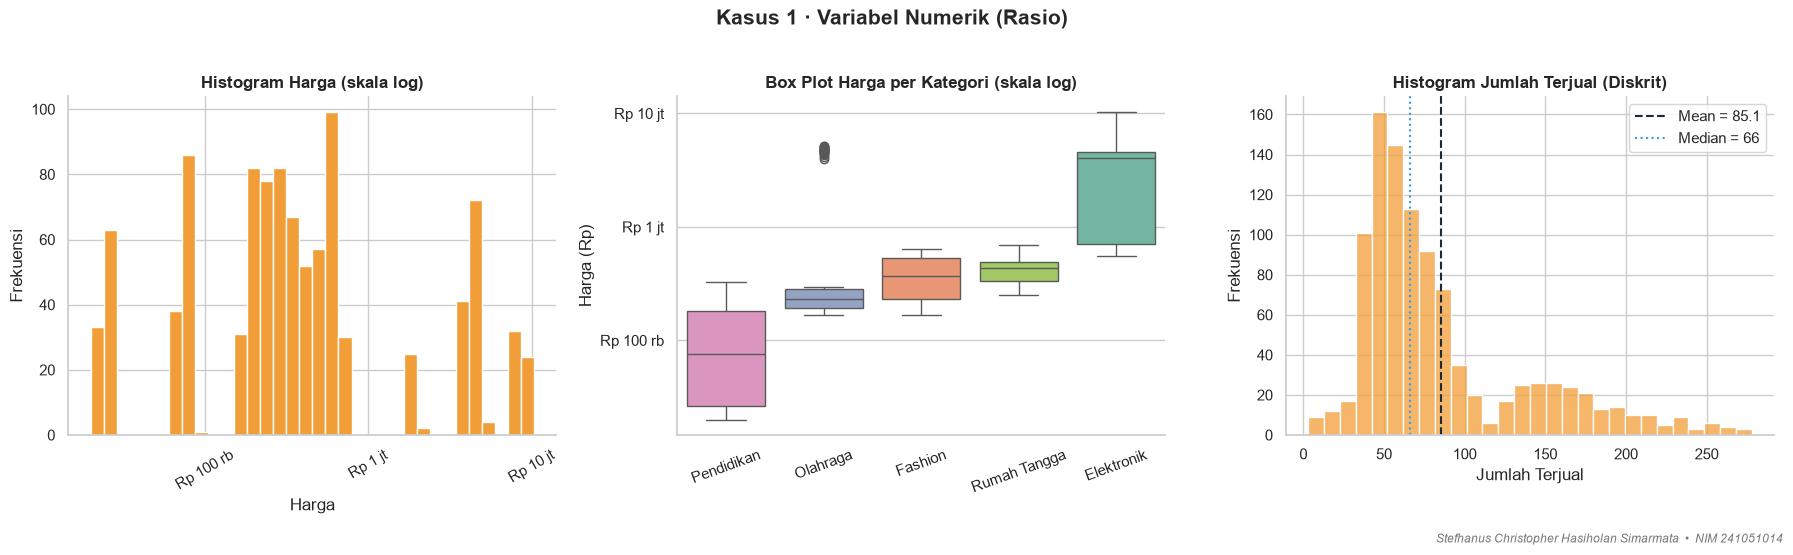

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5.5))

# (a) Histogram Harga — skala log
bins = np.logspace(np.log10(df1["Harga (Rp)"].min()), np.log10(df1["Harga (Rp)"].max()), 35)
ax[0].hist(df1["Harga (Rp)"], bins=bins, color=ORANYE, edgecolor="white")
ax[0].set_xscale("log"); ax[0].xaxis.set_major_formatter(mtick.FuncFormatter(fmt_rp))
ax[0].set_title("Histogram Harga (skala log)"); ax[0].set_xlabel("Harga"); ax[0].set_ylabel("Frekuensi")
ax[0].tick_params(axis="x", rotation=30)

# (b) Box plot Harga per kategori
urut = df1.groupby("Kategori")["Harga (Rp)"].median().sort_values().index
sns.boxplot(data=df1, x="Kategori", y="Harga (Rp)", order=urut, palette=kat_warna, ax=ax[1])
ax[1].set_yscale("log"); ax[1].yaxis.set_major_formatter(mtick.FuncFormatter(fmt_rp))
ax[1].set_title("Box Plot Harga per Kategori (skala log)"); ax[1].set_xlabel("")
ax[1].tick_params(axis="x", rotation=20)

# (c) Histogram Jumlah Terjual (diskrit)
sns.histplot(df1["Jumlah Terjual"], binwidth=10, color=ORANYE, edgecolor="white", ax=ax[2])
ax[2].axvline(df1["Jumlah Terjual"].mean(), color="#1b2a3a", ls="--", label=f"Mean = {df1['Jumlah Terjual'].mean():.1f}")
ax[2].axvline(df1["Jumlah Terjual"].median(), color=BIRU, ls=":", label=f"Median = {df1['Jumlah Terjual'].median():.0f}")
ax[2].legend(); ax[2].set_title("Histogram Jumlah Terjual (Diskrit)"); ax[2].set_ylabel("Frekuensi")
finalize(fig, "Kasus 1 · Variabel Numerik (Rasio)")

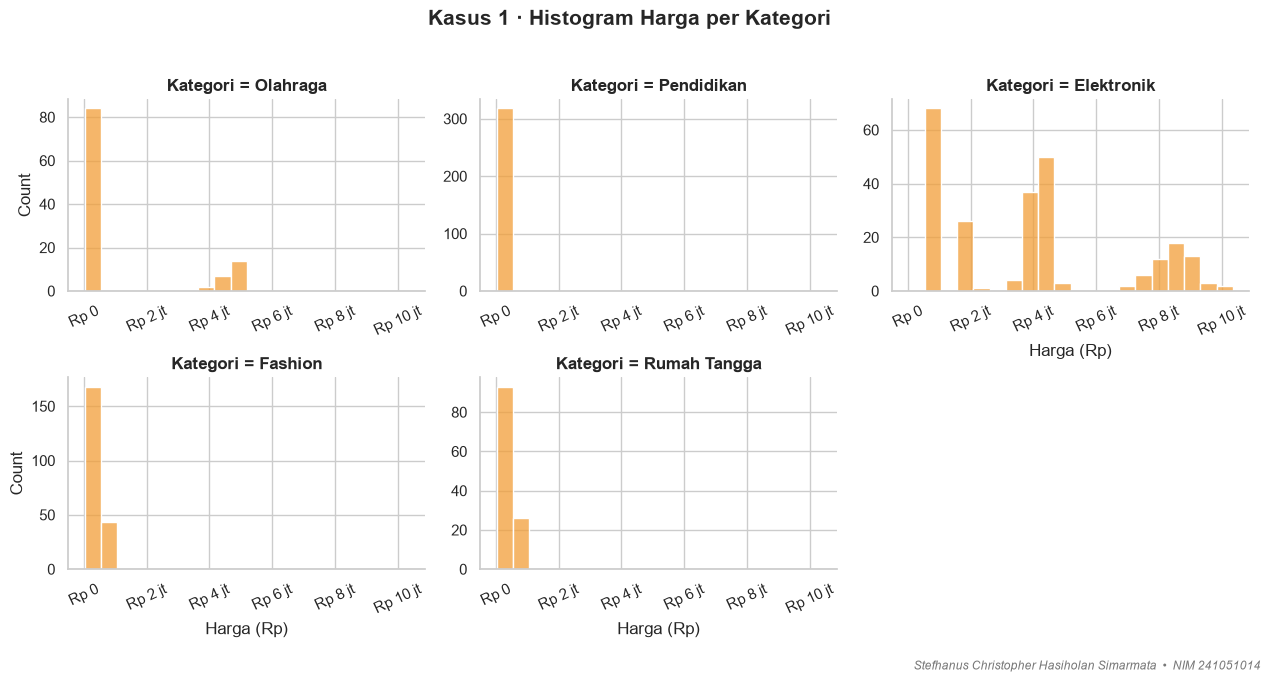

In [9]:
# Distribusi harga per kategori (sumbu bebas, karena rentang harga tiap kategori berbeda jauh)
g = sns.displot(df1, x="Harga (Rp)", col="Kategori", col_wrap=3, bins=20, color=ORANYE,
                facet_kws=dict(sharex=False, sharey=False), height=3.4, aspect=1.25)
for a in g.axes.flat:
    a.xaxis.set_major_formatter(mtick.FuncFormatter(fmt_rp)); a.tick_params(axis="x", rotation=25)
finalize(g.figure, "Kasus 1 · Histogram Harga per Kategori")

### 2.4 Waktu (Interval): Line Chart tren penjualan

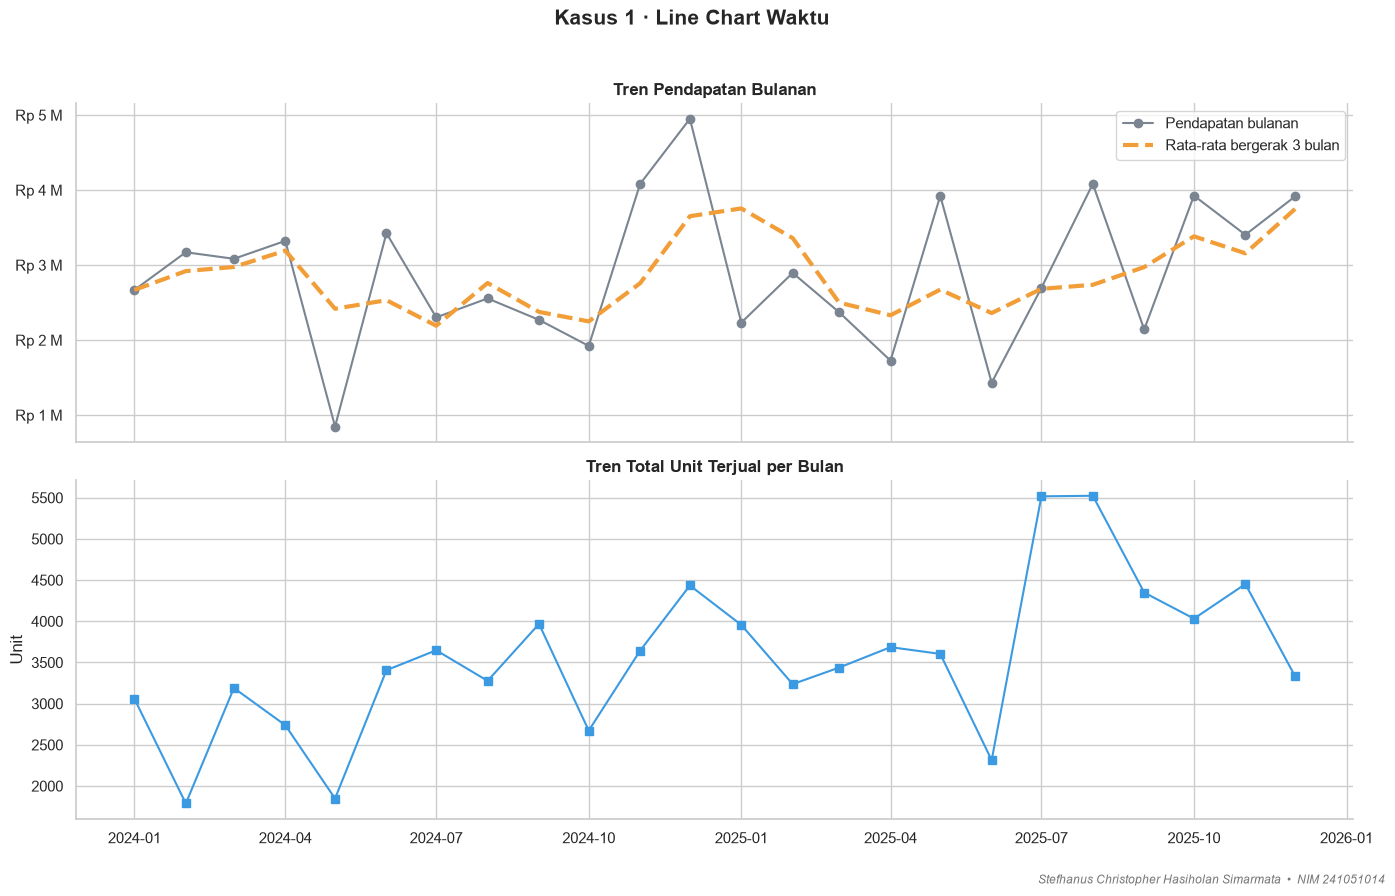

,Transaksi,Unit,Pendapatan,MA-3 Pendapatan
Tanggal,,,,
2024-01-01,39,3059,2669179000,"2,669,179,000.00"
2024-02-01,34,1788,3171560500,"2,920,369,750.00"
2024-03-01,46,3190,3084231000,"2,974,990,167.00"
2024-04-01,41,2738,3323167000,"3,192,986,167.00"
2024-05-01,26,1848,847688500,"2,418,362,167.00"
2024-06-01,46,3406,3425877000,"2,532,244,167.00"
2024-07-01,36,3648,2303018500,"2,192,194,667.00"
2024-08-01,43,3277,2555964500,"2,761,620,000.00"
2024-09-01,49,3968,2270126500,"2,376,369,833.00"


In [10]:
ts = df1.set_index("Tanggal")
bulanan = ts.resample("MS").agg(Transaksi=("Produk", "count"), Unit=("Jumlah Terjual", "sum"),
                                Pendapatan=("Pendapatan (Rp)", "sum"))
bulanan["MA-3 Pendapatan"] = bulanan["Pendapatan"].rolling(3, min_periods=1).mean()

fig, ax = plt.subplots(2, 1, figsize=(14, 9), sharex=True)
ax[0].plot(bulanan.index, bulanan["Pendapatan"], marker="o", color=ABU, label="Pendapatan bulanan")
ax[0].plot(bulanan.index, bulanan["MA-3 Pendapatan"], color=ORANYE, lw=3, ls="--", label="Rata-rata bergerak 3 bulan")
ax[0].yaxis.set_major_formatter(mtick.FuncFormatter(fmt_rp)); ax[0].legend()
ax[0].set_title("Tren Pendapatan Bulanan")
ax[1].plot(bulanan.index, bulanan["Unit"], marker="s", color=BIRU)
ax[1].set_title("Tren Total Unit Terjual per Bulan"); ax[1].set_ylabel("Unit")
finalize(fig, "Kasus 1 · Line Chart Waktu")
display(bulanan.round(0))

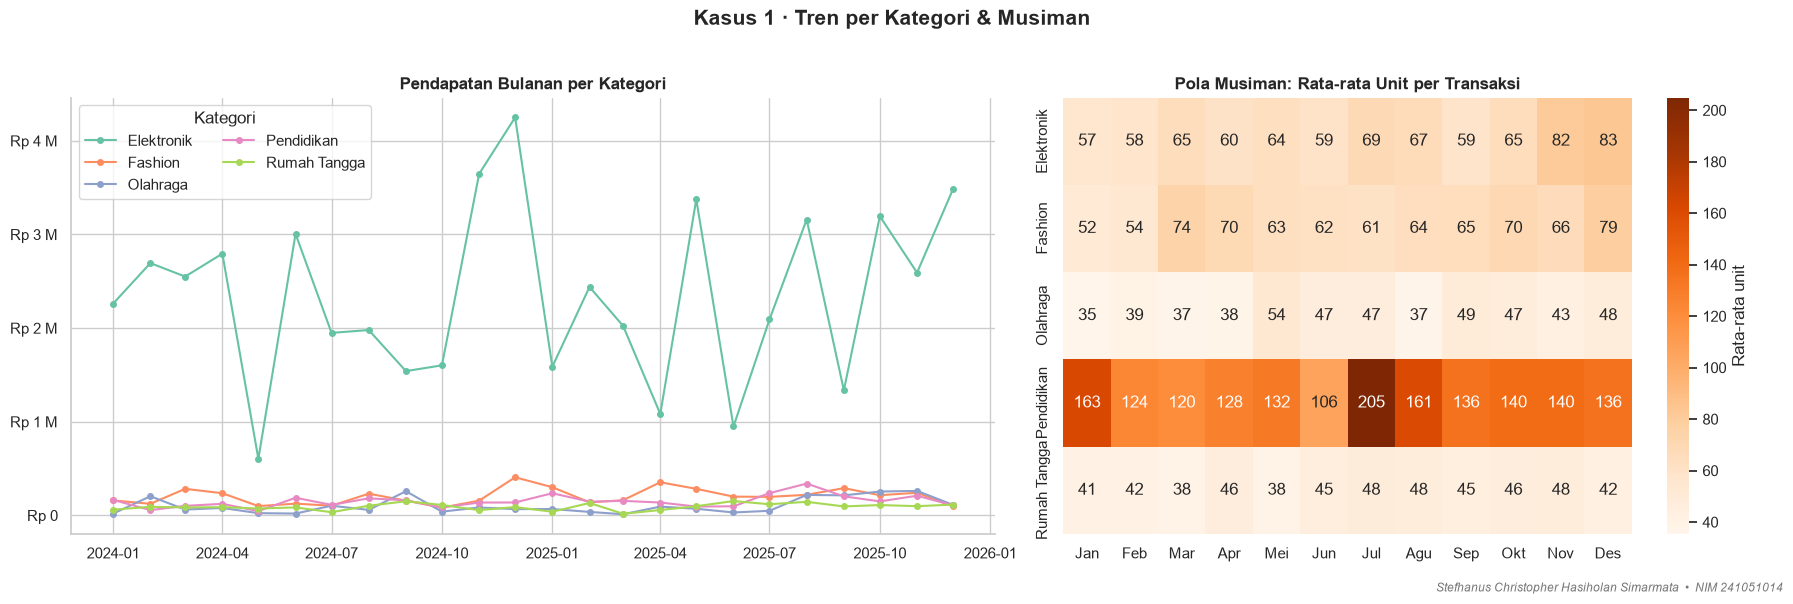

In [11]:
# Tren per kategori + heatmap pola musiman
per_kat = (df1.groupby([pd.Grouper(key="Tanggal", freq="MS"), "Kategori"])["Pendapatan (Rp)"]
              .sum().unstack(fill_value=0))
musim = df1.pivot_table(values="Jumlah Terjual", index="Kategori", columns=df1["Tanggal"].dt.month, aggfunc="mean")
musim.columns = ["Jan", "Feb", "Mar", "Apr", "Mei", "Jun", "Jul", "Agu", "Sep", "Okt", "Nov", "Des"]

fig, ax = plt.subplots(1, 2, figsize=(18, 6), gridspec_kw={"width_ratios": [1.3, 1]})
for k in per_kat.columns:
    ax[0].plot(per_kat.index, per_kat[k], marker="o", ms=4, label=k, color=kat_warna[k])
ax[0].yaxis.set_major_formatter(mtick.FuncFormatter(fmt_rp)); ax[0].legend(title="Kategori", ncol=2)
ax[0].set_title("Pendapatan Bulanan per Kategori")
sns.heatmap(musim, annot=True, fmt=".0f", cmap="Oranges", cbar_kws={"label": "Rata-rata unit"}, ax=ax[1])
ax[1].set_title("Pola Musiman: Rata-rata Unit per Transaksi"); ax[1].set_ylabel("")
finalize(fig, "Kasus 1 · Tren per Kategori & Musiman")

### 2.5 Insight Kasus 1

In [12]:
rev = df1.groupby("Produk")["Pendapatan (Rp)"].sum().sort_values(ascending=False)
bulan_puncak = bulanan["Pendapatan"].idxmax()
rho, p = stats.spearmanr(df1["Harga (Rp)"], df1["Jumlah Terjual"])
tahun = df1.groupby(df1["Tanggal"].dt.year).agg(Transaksi=("Produk", "count"), Unit=("Jumlah Terjual", "sum"), Pendapatan=("Pendapatan (Rp)", "sum"))

print(f"1. Total pendapatan  : Rp {df1['Pendapatan (Rp)'].sum():,.0f}  dari {len(df1):,} transaksi")
print(f"2. Produk terlaris (pendapatan): {rev.index[0]} (Rp {rev.iloc[0]:,.0f}); terendah: {rev.index[-1]}")
print(f"3. Bulan puncak pendapatan     : {bulan_puncak:%B %Y}")
print(f"4. Korelasi Spearman Harga vs Jumlah Terjual = {rho:.2f} (p = {p:.1e}) -> makin mahal, makin sedikit unit per transaksi")
g = (tahun.iloc[-1] / tahun.iloc[0] - 1) * 100
print(f"5. Pertumbuhan 2024 -> 2025: transaksi {g['Transaksi']:+.1f}%, unit {g['Unit']:+.1f}%, pendapatan {g['Pendapatan']:+.1f}%"
      " (pendapatan sangat dipengaruhi bauran produk mahal seperti Laptop/Smartphone)")
print(f"6. Harga sangat miring ke kanan (skewness = {df1['Harga (Rp)'].skew():.2f}) -> gunakan median & skala log, bukan mean saja")

1. Total pendapatan  : Rp 69,359,583,500  dari 1,000 transaksi
2. Produk terlaris (pendapatan): Smartphone (Rp 26,954,141,500); terendah: Dumbbell
3. Bulan puncak pendapatan     : December 2024
4. Korelasi Spearman Harga vs Jumlah Terjual = -0.63 (p = 9.6e-110) -> makin mahal, makin sedikit unit per transaksi
5. Pertumbuhan 2024 -> 2025: transaksi +6.2%, unit +25.9%, pendapatan +0.4% (pendapatan sangat dipengaruhi bauran produk mahal seperti Laptop/Smartphone)
6. Harga sangat miring ke kanan (skewness = 2.29) -> gunakan median & skala log, bukan mean saja


---
## 3. Bedah Kasus 2 — Dataset Profil Mahasiswa

| Kolom | Tipe data | Visualisasi |
|---|---|---|
| Jurusan | 🔵 Kategorik (Nominal) | Bar Chart |
| Semester | 🔵 Kategorik (**Ordinal**) — urutan 1 → 2 → 3 | Bar Chart **berurutan** |
| IPK, Usia | 🟠 Numerik (Kontinu) | Histogram (distribusi) / Box Plot (sebaran & outlier) |

### 3.1 Struktur data & statistik deskriptif

In [13]:
# Semester dijadikan Categorical *ordered* agar urutan 1 < 2 < ... < 8 dihormati pandas/seaborn
df2["Semester"] = pd.Categorical(df2["Semester"], categories=range(1, 9), ordered=True)
df2.info()

display(Markdown("**Statistik deskriptif — IPK & Usia (Numerik Kontinu)**"))
display(ringkasan_numerik(df2, ["IPK", "Usia"]))

display(Markdown("**Jurusan (Nominal) — frekuensi**"))
fj = df2["Jurusan"].value_counts()
display(pd.DataFrame({"Frekuensi": fj, "Persen (%)": (fj / len(df2) * 100).round(2)}))

display(Markdown("**Semester (Ordinal) — frekuensi berurutan + kumulatif**"))
fs = df2["Semester"].value_counts().sort_index()
display(pd.DataFrame({"Frekuensi": fs, "Persen (%)": (fs / len(df2) * 100).round(2),
                      "Kumulatif (%)": (fs.cumsum() / len(df2) * 100).round(2)}))
sem_num = df2["Semester"].astype(int)
print(f"Untuk data ordinal gunakan median/modus: Median semester = {int(sem_num.median())}, Modus = {int(sem_num.mode()[0])}")

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   Jurusan   1000 non-null   str     
 1   Semester  1000 non-null   category
 2   IPK       1000 non-null   float64 
 3   Usia      1000 non-null   int64   
dtypes: category(1), float64(1), int64(1), str(1)
memory usage: 36.8 KB


**Statistik deskriptif — IPK & Usia (Numerik Kontinu)**

,Count,Mean,Median,Std,Min,Q1,Q3,Max,IQR,Skewness,Kurtosis,CV (%)
IPK,"1,000.00",3.27,3.29,0.35,1.89,3.07,3.50,4.00,0.43,-0.63,1.22,10.81
Usia,"1,000.00",20.09,20.00,1.67,18.00,19.00,21.00,28.00,2.00,1.30,3.20,8.29


**Jurusan (Nominal) — frekuensi**

,Frekuensi,Persen (%)
Jurusan,,
Sistem Informasi,172,17.20
Teknik Informatika,171,17.10
Manajemen,165,16.50
Akuntansi,125,12.50
Psikologi,118,11.80
Ilmu Komunikasi,112,11.20
Teknik Sipil,75,7.50
Hukum,62,6.20


**Semester (Ordinal) — frekuensi berurutan + kumulatif**

,Frekuensi,Persen (%),Kumulatif (%)
Semester,,,
1,172,17.20,17.20
2,156,15.60,32.80
3,164,16.40,49.20
4,124,12.40,61.60
5,115,11.50,73.10
6,121,12.10,85.20
7,86,8.60,93.80
8,62,6.20,100.00


Untuk data ordinal gunakan median/modus: Median semester = 4, Modus = 1


### 3.2 Nominal (Jurusan) vs Ordinal (Semester)

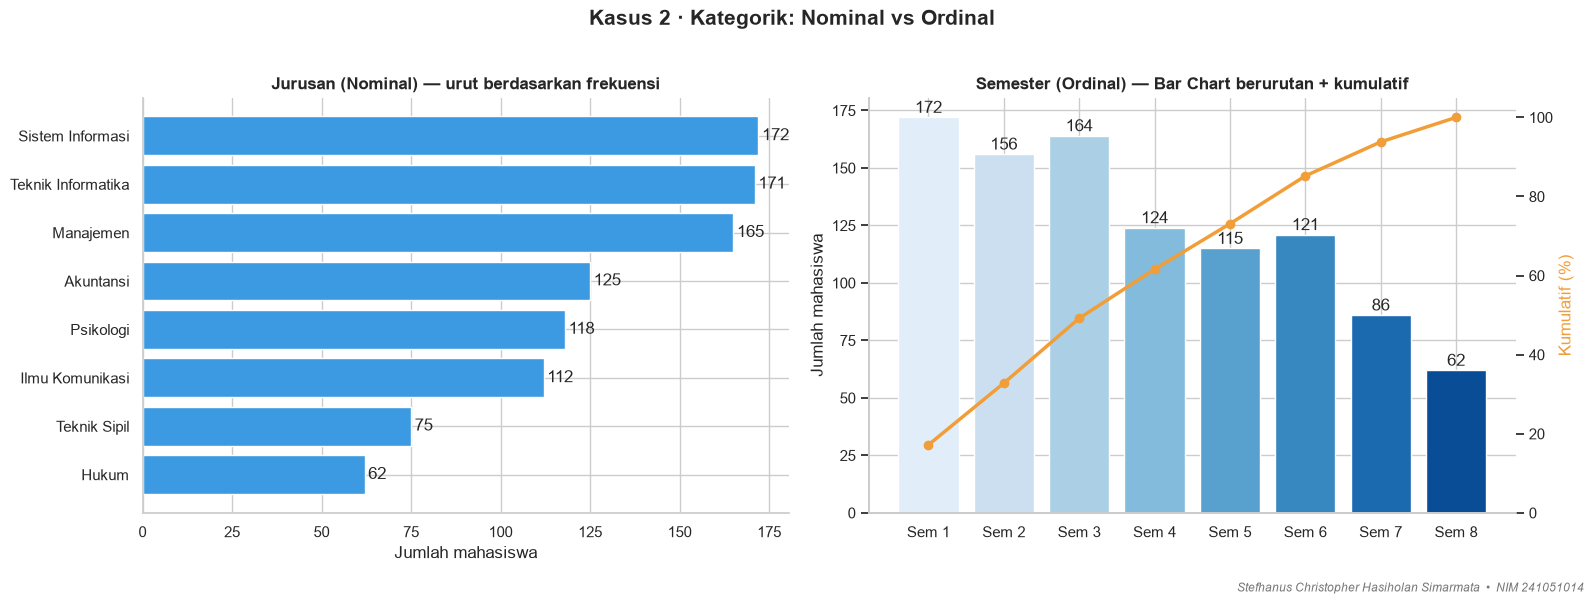

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6))

# Nominal -> urutkan berdasarkan frekuensi
fj = df2["Jurusan"].value_counts().sort_values()
ax[0].barh(fj.index, fj.values, color=BIRU)
for i, v in enumerate(fj.values): ax[0].text(v + 1, i, str(v), va="center")
ax[0].set_title("Jurusan (Nominal) — urut berdasarkan frekuensi"); ax[0].set_xlabel("Jumlah mahasiswa")

# Ordinal -> JANGAN urutkan berdasarkan frekuensi; pertahankan urutan semester
fs = df2["Semester"].value_counts().sort_index()
cols = sns.color_palette("Blues", 8)
ax[1].bar([f"Sem {i}" for i in fs.index], fs.values, color=cols)
for i, v in enumerate(fs.values): ax[1].text(i, v + 2, str(v), ha="center")
ax2 = ax[1].twinx()
ax2.plot(range(8), fs.cumsum() / fs.sum() * 100, color=ORANYE, marker="o", lw=2.5)
ax2.set_ylim(0, 105); ax2.set_ylabel("Kumulatif (%)", color=ORANYE); ax2.grid(False)
ax[1].set_title("Semester (Ordinal) — Bar Chart berurutan + kumulatif"); ax[1].set_ylabel("Jumlah mahasiswa")
finalize(fig, "Kasus 2 · Kategorik: Nominal vs Ordinal")

### 3.3 Numerik Kontinu: IPK & Usia (Histogram, Box Plot, outlier)

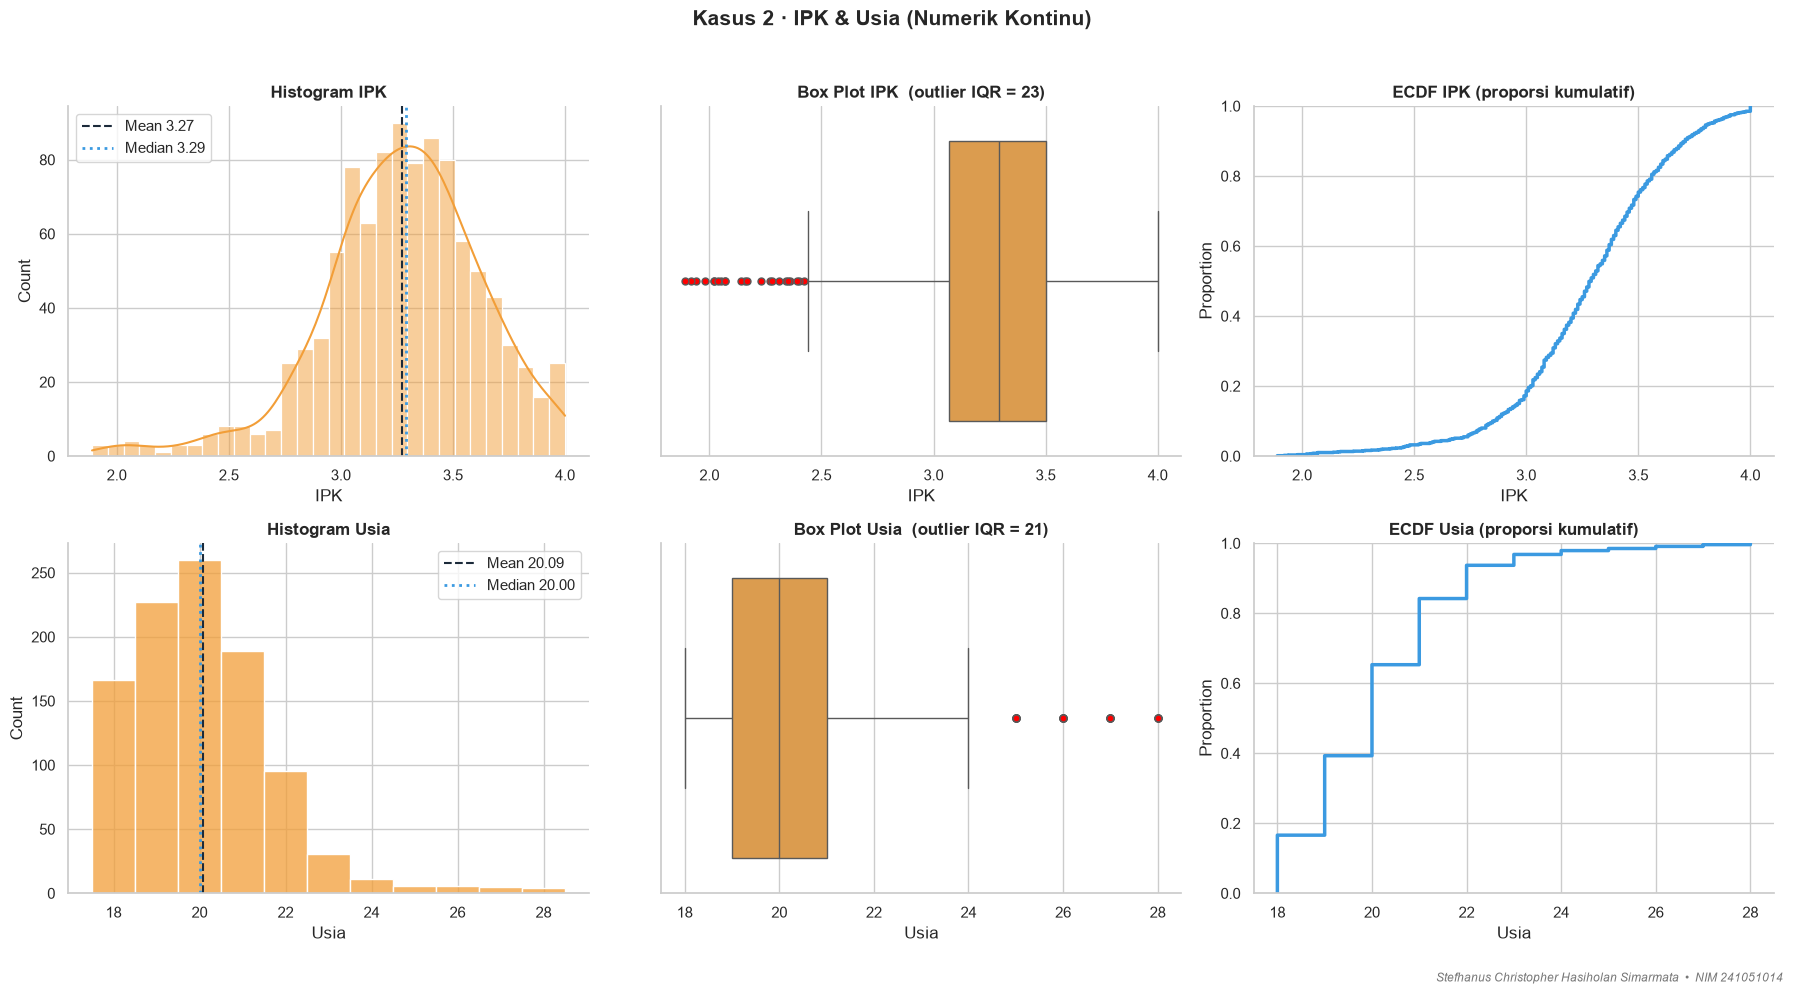

In [15]:
fig, ax = plt.subplots(2, 3, figsize=(18, 10))

for baris, (kol, warna, disc) in enumerate([("IPK", ORANYE, False), ("Usia", ORANYE, True)]):
    s = df2[kol]
    sns.histplot(s, kde=not disc, discrete=disc, bins=None if disc else 30, color=warna, edgecolor="white", ax=ax[baris, 0])
    ax[baris, 0].axvline(s.mean(), color="#1b2a3a", ls="--", label=f"Mean {s.mean():.2f}")
    ax[baris, 0].axvline(s.median(), color=BIRU, ls=":", lw=2, label=f"Median {s.median():.2f}")
    ax[baris, 0].legend(); ax[baris, 0].set_title(f"Histogram {kol}")

    sns.boxplot(x=s, color=warna, ax=ax[baris, 1], flierprops=dict(marker="o", markerfacecolor="red", markersize=5))
    n_out = int(outlier_iqr(s)[0].sum())
    ax[baris, 1].set_title(f"Box Plot {kol}  (outlier IQR = {n_out})")

    sns.ecdfplot(s, color=BIRU, lw=2.5, ax=ax[baris, 2])
    ax[baris, 2].set_title(f"ECDF {kol} (proporsi kumulatif)")
finalize(fig, "Kasus 2 · IPK & Usia (Numerik Kontinu)")

In [16]:
mask, bb, ba = outlier_iqr(df2["IPK"])
print(f"Batas IQR IPK : bawah = {bb:.2f}, atas = {ba:.2f}  ->  {int(mask.sum())} outlier ({mask.mean() * 100:.1f}%)")
display(df2[mask].sort_values("IPK").head(8))
mask_u, bbu, bau = outlier_iqr(df2["Usia"])
print(f"Batas IQR Usia: bawah = {bbu:.1f}, atas = {bau:.1f}  ->  {int(mask_u.sum())} outlier (mahasiswa berusia lebih tua)")

Batas IQR IPK : bawah = 2.42, atas = 4.15  ->  23 outlier (2.3%)


,Jurusan,Semester,IPK,Usia
963,Manajemen,2,1.89,18
375,Teknik Informatika,4,1.92,19
322,Psikologi,2,1.94,18
653,Manajemen,8,1.98,21
834,Sistem Informasi,6,2.02,28
713,Teknik Informatika,4,2.02,19
939,Ilmu Komunikasi,2,2.04,19
455,Teknik Informatika,2,2.05,18


Batas IQR Usia: bawah = 16.0, atas = 24.0  ->  21 outlier (mahasiswa berusia lebih tua)


### 3.4 Hubungan antar variabel

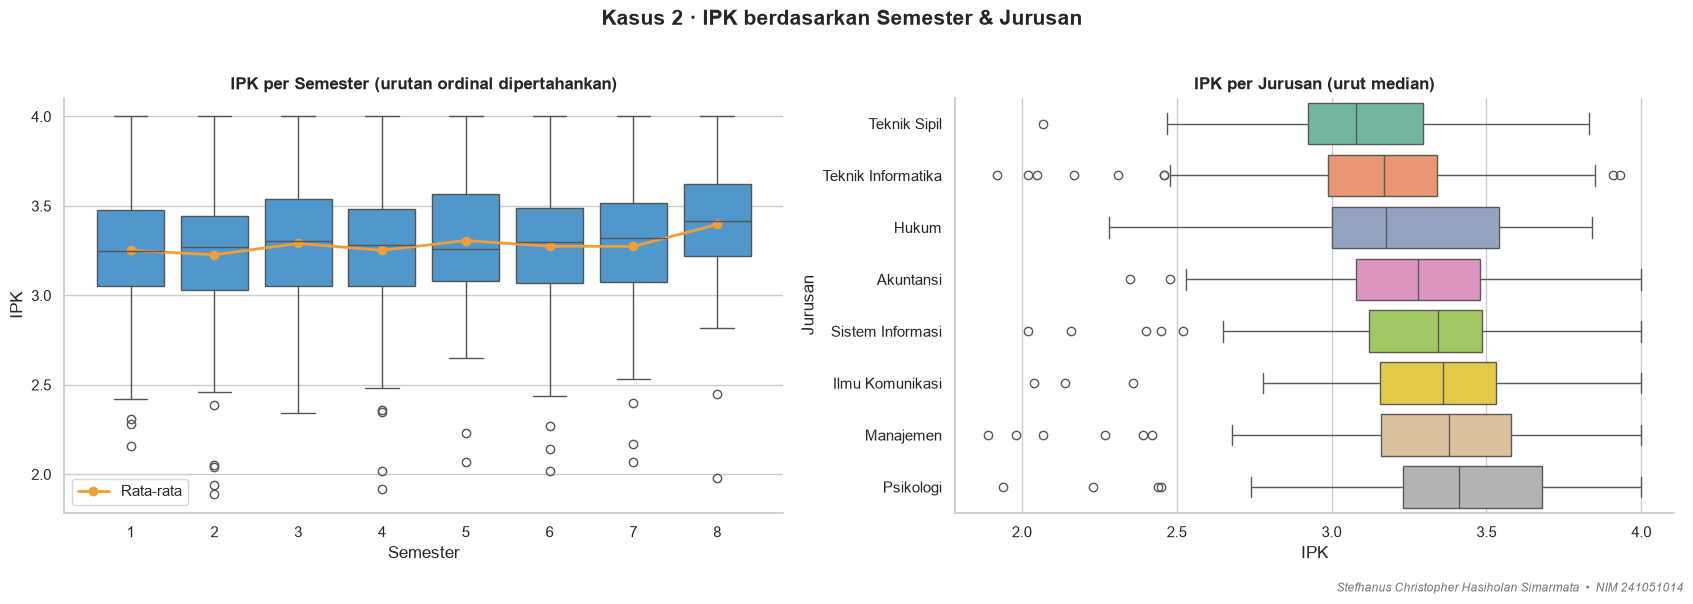

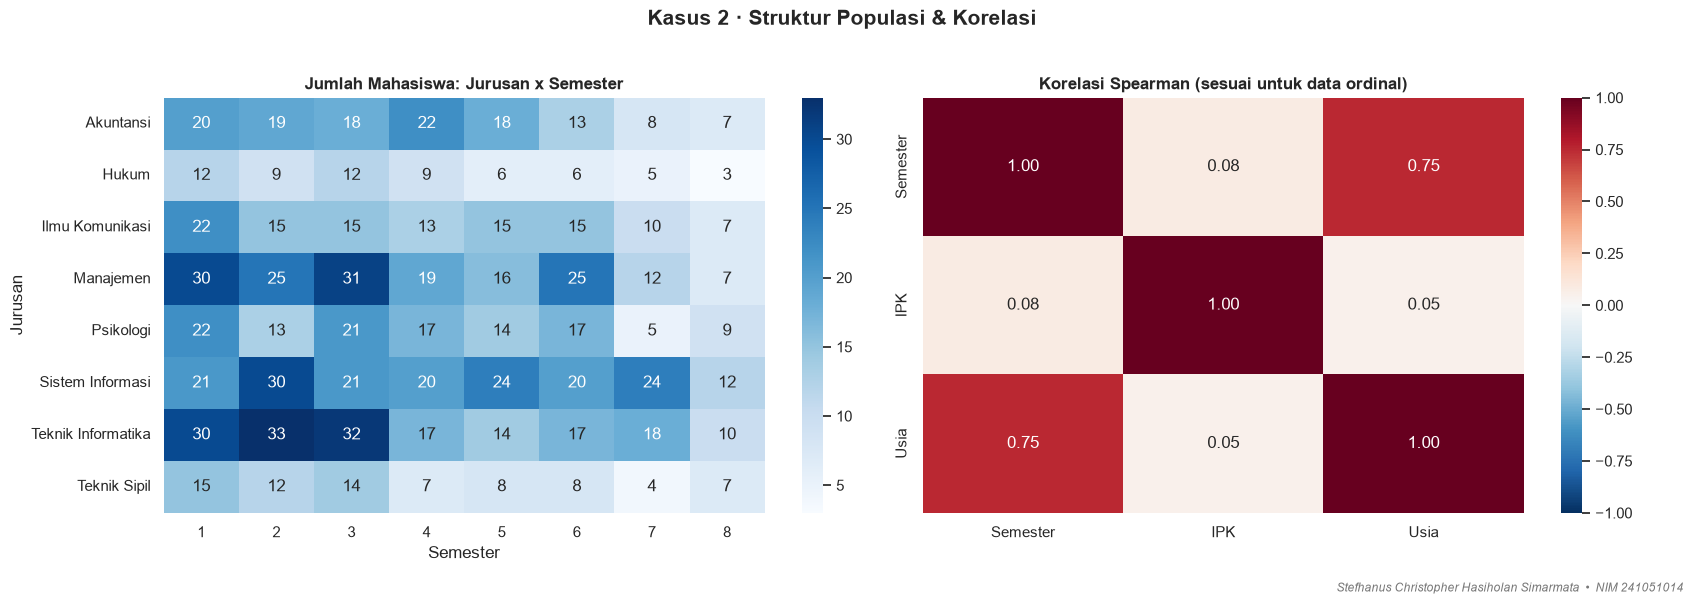

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(17, 6))
sns.boxplot(data=df2, x="Semester", y="IPK", color=BIRU, ax=ax[0])
ax[0].plot(range(8), df2.groupby("Semester", observed=True)["IPK"].mean().values, "o-", color=ORANYE, lw=2, label="Rata-rata")
ax[0].legend(); ax[0].set_title("IPK per Semester (urutan ordinal dipertahankan)")

urut = df2.groupby("Jurusan")["IPK"].median().sort_values().index
sns.boxplot(data=df2, y="Jurusan", x="IPK", order=urut, palette="Set2", ax=ax[1])
ax[1].set_title("IPK per Jurusan (urut median)")
finalize(fig, "Kasus 2 · IPK berdasarkan Semester & Jurusan")

fig, ax = plt.subplots(1, 2, figsize=(17, 6))
ct = pd.crosstab(df2["Jurusan"], df2["Semester"])
sns.heatmap(ct, annot=True, fmt="d", cmap="Blues", ax=ax[0]); ax[0].set_title("Jumlah Mahasiswa: Jurusan x Semester")
kor = pd.DataFrame({"Semester": sem_num, "IPK": df2["IPK"], "Usia": df2["Usia"]}).corr(method="spearman")
sns.heatmap(kor, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax[1])
ax[1].set_title("Korelasi Spearman (sesuai untuk data ordinal)")
finalize(fig, "Kasus 2 · Struktur Populasi & Korelasi")

### 3.5 Insight & uji statistik Kasus 2

In [18]:
H, p_kw = stats.kruskal(*[g["IPK"].values for _, g in df2.groupby("Jurusan")])
rho_s, p_s = stats.spearmanr(sem_num, df2["IPK"])
rho_u, p_u = stats.spearmanr(sem_num, df2["Usia"])
top = df2.groupby("Jurusan")["IPK"].mean().sort_values(ascending=False)

print(f"1. Rata-rata IPK = {df2['IPK'].mean():.2f}, median = {df2['IPK'].median():.2f}; {(df2['IPK'] >= 3.5).mean() * 100:.1f}% mahasiswa ber-IPK >= 3,50")
print(f"2. Jurusan IPK tertinggi: {top.index[0]} ({top.iloc[0]:.2f}); terendah: {top.index[-1]} ({top.iloc[-1]:.2f})")
print(f"3. Kruskal-Wallis IPK antar-jurusan: H = {H:.1f}, p = {p_kw:.1e} -> " + ("ada perbedaan signifikan" if p_kw < 0.05 else "tidak signifikan"))
print(f"4. Spearman Semester-IPK = {rho_s:.2f} (p = {p_s:.2f}); Semester-Usia = {rho_u:.2f} (p = {p_u:.1e})")
print(f"5. Distribusi IPK sedikit miring ke kiri (skewness = {df2['IPK'].skew():.2f}) akibat segelintir IPK rendah (outlier)")

1. Rata-rata IPK = 3.27, median = 3.29; 25.8% mahasiswa ber-IPK >= 3,50
2. Jurusan IPK tertinggi: Psikologi (3.41); terendah: Teknik Sipil (3.10)
3. Kruskal-Wallis IPK antar-jurusan: H = 90.3, p = 1.1e-16 -> ada perbedaan signifikan
4. Spearman Semester-IPK = 0.08 (p = 0.01); Semester-Usia = 0.75 (p = 2.0e-181)
5. Distribusi IPK sedikit miring ke kiri (skewness = -0.63) akibat segelintir IPK rendah (outlier)


---
## 4. Bedah Kasus 3 — Dataset Pengamatan Cuaca

| Kolom | Tipe data | Catatan |
|---|---|---|
| Kota, Kondisi | 🔵 Kategorik (Nominal) | Label teks tanpa urutan |
| Suhu (°C) | 🟠 Numerik – **Interval** | Jarak antar suhu sama, tetapi 0 °C bukan "tidak ada suhu"; **rasio tidak berlaku** |
| Kelembaban (%) | 🟠 Numerik – **Rasio** | 0% benar-benar tidak ada kelembaban (nol absolut) |

### 4.1 Struktur data & statistik deskriptif

In [19]:
df3.info()
display(Markdown("**Statistik deskriptif — Suhu (Interval) & Kelembaban (Rasio)**"))
display(ringkasan_numerik(df3, ["Suhu (°C)", "Kelembaban (%)"]))

display(Markdown("**Rata-rata per kota**"))
display(df3.groupby("Kota").agg(Observasi=("Suhu (°C)", "size"), Suhu_rata2=("Suhu (°C)", "mean"),
                                Suhu_std=("Suhu (°C)", "std"), Lembab_rata2=("Kelembaban (%)", "mean")).sort_values("Suhu_rata2", ascending=False))

fk = df3["Kondisi"].value_counts()
display(Markdown("**Kondisi cuaca (Nominal)**"))
display(pd.DataFrame({"Frekuensi": fk, "Persen (%)": (fk / len(df3) * 100).round(2)}))

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Kota            1000 non-null   str    
 1   Suhu (°C)       1000 non-null   float64
 2   Kelembaban (%)  1000 non-null   int64  
 3   Kondisi         1000 non-null   str    
dtypes: float64(1), int64(1), str(2)
memory usage: 44.8 KB


**Statistik deskriptif — Suhu (Interval) & Kelembaban (Rasio)**

,Count,Mean,Median,Std,Min,Q1,Q3,Max,IQR,Skewness,Kurtosis,CV (%)
Suhu (°C),"1,000.00",30.43,30.80,2.48,20.30,29.40,32.00,36.50,2.60,-0.90,1.24,8.15
Kelembaban (%),"1,000.00",76.89,77.00,9.45,48.00,70.00,84.00,100.00,14.00,-0.12,-0.11,12.29


**Rata-rata per kota**

,Observasi,Suhu_rata2,Suhu_std,Lembab_rata2
Kota,,,,
Surabaya,98,31.97,1.89,70.46
Palembang,103,31.61,1.66,77.22
Jakarta,100,31.47,1.88,74.73
Makassar,101,31.23,1.51,77.00
Jayapura,84,31.03,1.58,80.18
Semarang,97,30.83,1.59,75.10
Medan,95,30.82,1.83,77.71
Denpasar,109,30.59,1.33,78.34
Yogyakarta,118,29.60,1.81,76.87


**Kondisi cuaca (Nominal)**

,Frekuensi,Persen (%)
Kondisi,,
Cerah,369,36.90
Berawan,291,29.10
Hujan,290,29.00
Hujan Lebat,50,5.00


### 4.2 Nominal: Kota & Kondisi

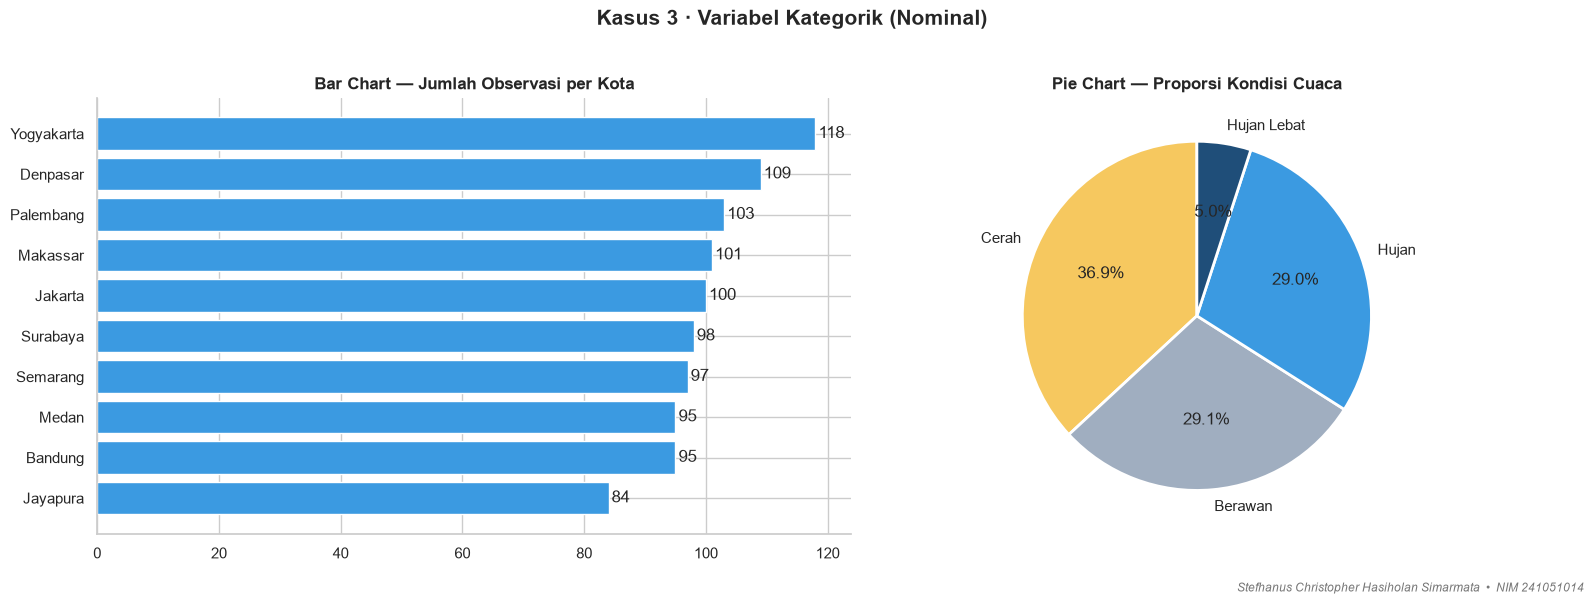

In [20]:
WARNA_KONDISI = {"Cerah": "#F6C85F", "Berawan": "#A0AEC0", "Hujan": BIRU, "Hujan Lebat": "#1F4E79"}
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
fkota = df3["Kota"].value_counts().sort_values()
ax[0].barh(fkota.index, fkota.values, color=BIRU)
for i, v in enumerate(fkota.values): ax[0].text(v + 0.5, i, str(v), va="center")
ax[0].set_title("Bar Chart — Jumlah Observasi per Kota")

fk = df3["Kondisi"].value_counts().reindex(["Cerah", "Berawan", "Hujan", "Hujan Lebat"])
ax[1].pie(fk.values, labels=fk.index, autopct="%1.1f%%", startangle=90, colors=[WARNA_KONDISI[k] for k in fk.index],
          wedgeprops=dict(edgecolor="white", linewidth=2))
ax[1].set_title("Pie Chart — Proporsi Kondisi Cuaca")
finalize(fig, "Kasus 3 · Variabel Kategorik (Nominal)")

### 4.3 Suhu (Interval) & Kelembaban (Rasio)

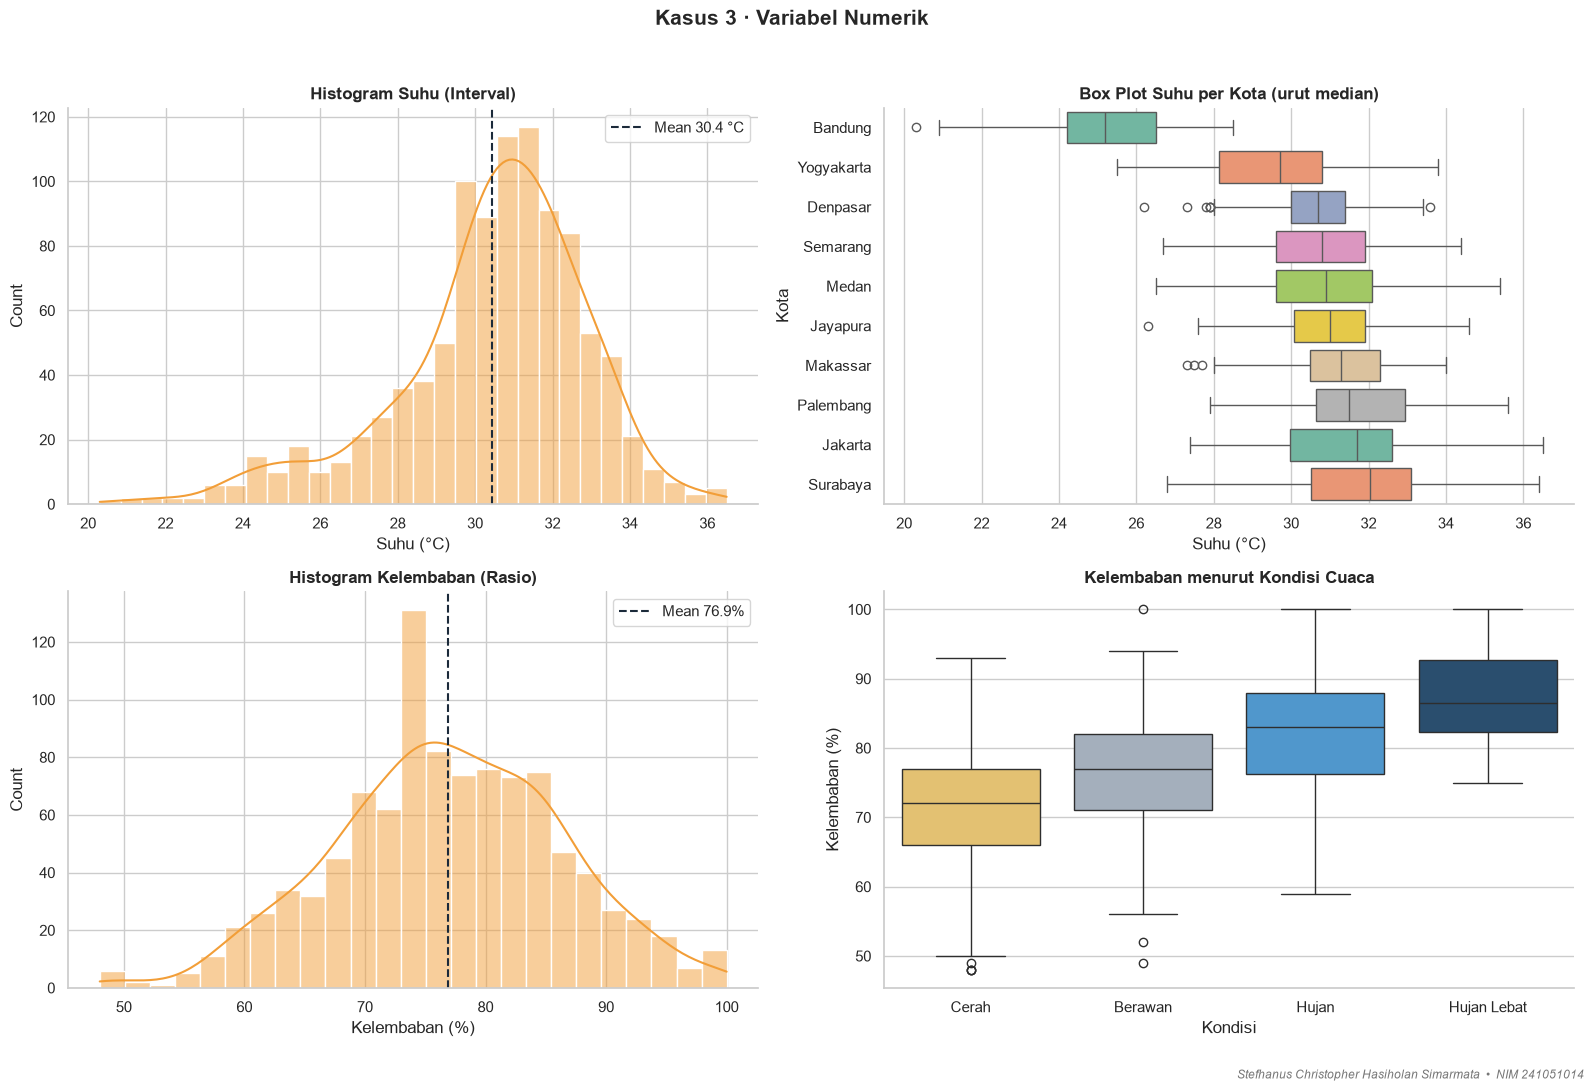

In [21]:
fig, ax = plt.subplots(2, 2, figsize=(16, 11))

sns.histplot(df3["Suhu (°C)"], kde=True, bins=30, color=ORANYE, edgecolor="white", ax=ax[0, 0])
ax[0, 0].axvline(df3["Suhu (°C)"].mean(), color="#1b2a3a", ls="--", label=f"Mean {df3['Suhu (°C)'].mean():.1f} °C")
ax[0, 0].legend(); ax[0, 0].set_title("Histogram Suhu (Interval)")

urut = df3.groupby("Kota")["Suhu (°C)"].median().sort_values().index
sns.boxplot(data=df3, y="Kota", x="Suhu (°C)", order=urut, palette="Set2", ax=ax[0, 1])
ax[0, 1].set_title("Box Plot Suhu per Kota (urut median)")

sns.histplot(df3["Kelembaban (%)"], kde=True, bins=25, color=ORANYE, edgecolor="white", ax=ax[1, 0])
ax[1, 0].axvline(df3["Kelembaban (%)"].mean(), color="#1b2a3a", ls="--", label=f"Mean {df3['Kelembaban (%)'].mean():.1f}%")
ax[1, 0].legend(); ax[1, 0].set_title("Histogram Kelembaban (Rasio)")

sns.boxplot(data=df3, x="Kondisi", y="Kelembaban (%)", order=["Cerah", "Berawan", "Hujan", "Hujan Lebat"],
            palette=WARNA_KONDISI, ax=ax[1, 1])
ax[1, 1].set_title("Kelembaban menurut Kondisi Cuaca")
finalize(fig, "Kasus 3 · Variabel Numerik")

### 4.4 Hubungan: Suhu vs Kelembaban & kondisi per kota

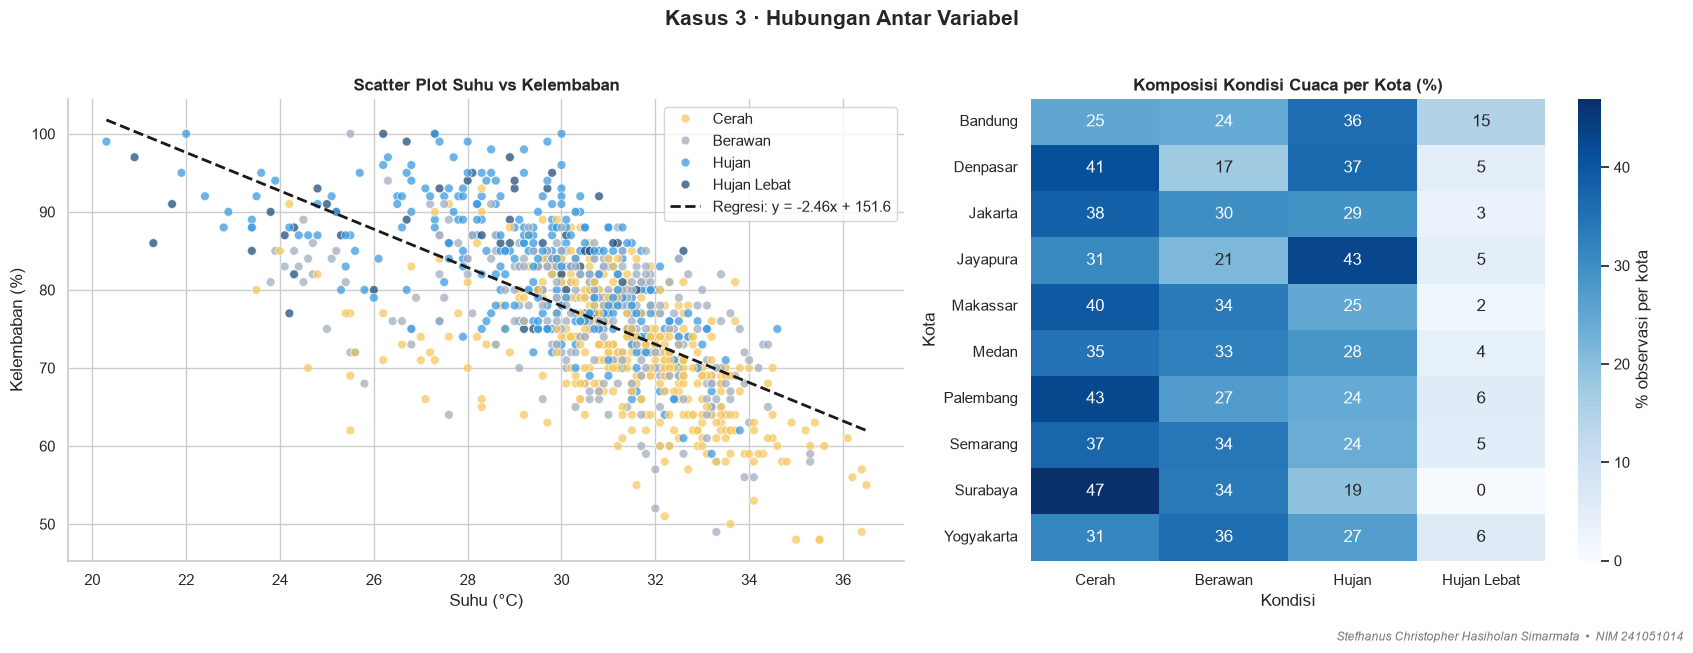

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(17, 6.5), gridspec_kw={"width_ratios": [1.3, 1]})
sns.scatterplot(data=df3, x="Suhu (°C)", y="Kelembaban (%)", hue="Kondisi", hue_order=list(WARNA_KONDISI),
                palette=WARNA_KONDISI, alpha=0.75, s=40, ax=ax[0])
koef = np.polyfit(df3["Suhu (°C)"], df3["Kelembaban (%)"], 1)
xs = np.linspace(df3["Suhu (°C)"].min(), df3["Suhu (°C)"].max(), 50)
ax[0].plot(xs, np.polyval(koef, xs), "k--", lw=2, label=f"Regresi: y = {koef[0]:.2f}x + {koef[1]:.1f}")
ax[0].legend(); ax[0].set_title("Scatter Plot Suhu vs Kelembaban")

ct = pd.crosstab(df3["Kota"], df3["Kondisi"], normalize="index")[list(WARNA_KONDISI)] * 100
sns.heatmap(ct, annot=True, fmt=".0f", cmap="Blues", cbar_kws={"label": "% observasi per kota"}, ax=ax[1])
ax[1].set_title("Komposisi Kondisi Cuaca per Kota (%)")
finalize(fig, "Kasus 3 · Hubungan Antar Variabel")

### 4.5 Demonstrasi: kenapa rasio **tidak berlaku** pada Suhu °C tetapi berlaku pada Kelembaban?

Pada skala **interval**, titik nol ditentukan secara sembarang (0 °C = titik beku air), sehingga perbandingan rasio tidak bermakna. Jika dikonversi ke Kelvin (nol absolut), barulah rasio bermakna.

In [23]:
a, b = 10, 20
print("SUHU (Interval)")
print(f"  Rasio dalam °C   : {b}/{a} = {b / a:.2f}x   -> MENYESATKAN (nol Celsius bukan nol absolut)")
print(f"  Rasio dalam Kelvin: {b + 273.15:.2f}/{a + 273.15:.2f} = {(b + 273.15) / (a + 273.15):.3f}x -> 20 °C hanya ~{(b + 273.15) / (a + 273.15):.2f}x lebih panas dari 10 °C")
print("\nKELEMBABAN (Rasio)")
print(f"  80% / 40% = {80 / 40:.1f}x -> VALID: nol absolut, 80% memang 2x lebih lembab dari 40%")

r, p = stats.pearsonr(df3["Suhu (°C)"], df3["Kelembaban (%)"])
panas = df3.groupby("Kota")["Suhu (°C)"].mean().sort_values(ascending=False)
hujan = df3.assign(h=df3["Kondisi"].isin(["Hujan", "Hujan Lebat"])).groupby("Kota")["h"].mean().sort_values(ascending=False) * 100
print("\nINSIGHT KASUS 3")
print(f"1. Korelasi Pearson Suhu vs Kelembaban = {r:.2f} (p = {p:.1e}) -> makin panas, kelembaban relatif makin rendah")
print(f"2. Kota terpanas: {panas.index[0]} ({panas.iloc[0]:.1f} °C); terdingin: {panas.index[-1]} ({panas.iloc[-1]:.1f} °C)")
print(f"3. Kota dengan hari hujan terbanyak: {hujan.index[0]} ({hujan.iloc[0]:.1f}%); paling sedikit: {hujan.index[-1]} ({hujan.iloc[-1]:.1f}%)")
print(f"4. Total hari hujan (Hujan + Hujan Lebat): {df3['Kondisi'].isin(['Hujan', 'Hujan Lebat']).mean() * 100:.1f}%")

SUHU (Interval)
  Rasio dalam °C   : 20/10 = 2.00x   -> MENYESATKAN (nol Celsius bukan nol absolut)
  Rasio dalam Kelvin: 293.15/283.15 = 1.035x -> 20 °C hanya ~1.04x lebih panas dari 10 °C

KELEMBABAN (Rasio)
  80% / 40% = 2.0x -> VALID: nol absolut, 80% memang 2x lebih lembab dari 40%

INSIGHT KASUS 3
1. Korelasi Pearson Suhu vs Kelembaban = -0.65 (p = 9.7e-119) -> makin panas, kelembaban relatif makin rendah
2. Kota terpanas: Surabaya (32.0 °C); terdingin: Bandung (25.2 °C)
3. Kota dengan hari hujan terbanyak: Bandung (50.5%); paling sedikit: Surabaya (19.4%)
4. Total hari hujan (Hujan + Hujan Lebat): 34.0%


---
## 5. Kesimpulan

| Kasus | Temuan utama | Pelajaran tipe data |
|---|---|---|
| **1 – Penjualan** | Elektronik menyumbang pendapatan terbesar, Pendidikan unit terbanyak; volume transaksi & unit naik dari 2024 ke 2025 serta ada pola musiman; harga makin tinggi → unit per transaksi makin rendah | Nominal → Bar/Pie · Kontinu-Rasio → Histogram (skala log bila miring) · Waktu → Line Chart |
| **2 – Mahasiswa** | IPK berpusat di ±3,3 dengan sedikit outlier rendah; usia naik seiring semester; IPK berbeda antar jurusan | Ordinal harus **berurutan** (bukan diurutkan frekuensi) & pakai median/Spearman |
| **3 – Cuaca** | Suhu & kelembaban berkorelasi negatif; kondisi hujan meningkat pada kelembaban tinggi; Bandung paling sejuk | Interval (suhu) **tanpa rasio**, Rasio (kelembaban) punya nol absolut |

**Dashboard interaktif:** jalankan `streamlit run streamlit_app.py` (file terpisah, sudah memuat Nama & NIM di sidebar, header, dan footer).

---
<div style="text-align:right"><i>Disusun oleh <b>Stefhanus Christopher Hasiholan Simarmata</b> — NIM <b>241051014</b></i></div>